In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import drive

from scipy.stats import loguniform, randint

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

BASE_PATH = "/content/drive/MyDrive/ML_lab"
CSV_PATH = os.path.join(BASE_PATH, "BreaKHis_metadata.csv")
IMAGE_ROOT = os.path.join(BASE_PATH, "BreaKHis_v1")

IMAGE_SIZE = (16, 16)
SAMPLES_PER_CLASS = 100
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
N_ITER_SEARCH = 20

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

In [ ]:
drive.mount("/content/drive")

metadata = pd.read_csv(CSV_PATH)

metadata["label"] = metadata["filename"].apply(
    lambda path: (
        "benign" if "/benign/" in str(path).lower()
        else "malignant" if "/malignant/" in str(path).lower()
        else None
    )
)

metadata = metadata.dropna(subset=["label"]).reset_index(drop=True)

print("Metadata shape:", metadata.shape)
print("\nClass distribution:")
print(metadata["label"].value_counts())
print("\nMetadata columns:")
print(metadata.columns.tolist())

Mounted at /content/drive
Metadata shape: (39545, 5)

Class distribution:
label
malignant    27145
benign       12400
Name: count, dtype: int64

Metadata columns:
['fold', 'mag', 'grp', 'filename', 'label']


In [ ]:
def locate_image(filename):
    relative_path = str(filename).replace("\\", "/").lstrip("/")

    candidates = [
        os.path.join(BASE_PATH, relative_path),
        os.path.join(IMAGE_ROOT, relative_path)
    ]

    if relative_path.startswith("BreaKHis_v1/"):
        short_path = relative_path.split("BreaKHis_v1/", 1)[1]

        candidates.extend([
            os.path.join(IMAGE_ROOT, short_path),
            os.path.join(IMAGE_ROOT, "BreaKHis_v1", short_path)
        ])

    for candidate in candidates:
        if os.path.isfile(candidate):
            return candidate

    return None


def load_project_dataset(dataframe):
    features = []
    labels = []
    missing_files = 0

    for _, row in dataframe.iterrows():
        image_path = locate_image(row["filename"])

        if image_path is None:
            missing_files += 1
            continue

        try:
            with Image.open(image_path) as image:
                image = image.convert("L")
                image = image.resize(IMAGE_SIZE)
                image_array = np.asarray(image, dtype=np.float32) / 255.0

            features.append(image_array.flatten())
            labels.append(1 if row["label"] == "malignant" else 0)

        except (OSError, ValueError):
            missing_files += 1

    X = np.asarray(features, dtype=np.float32).reshape(-1, 256)
    y = np.asarray(labels, dtype=np.int64)

    return X, y, missing_files

In [ ]:
class_counts = metadata["label"].value_counts()

if any(class_counts.get(label, 0) < SAMPLES_PER_CLASS
       for label in ["benign", "malignant"]):
    raise ValueError("Insufficient images in one or both classes.")

project_subset = (
    metadata.groupby("label", group_keys=False)
    .sample(n=SAMPLES_PER_CLASS, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

X_project, y_project, missing_files = load_project_dataset(project_subset)

print("Dataset shape:", X_project.shape)
print("Loaded images:", len(y_project))
print("Missing or unreadable images:", missing_files)
print("Benign images:", np.sum(y_project == 0))
print("Malignant images:", np.sum(y_project == 1))

if len(y_project) != 200:
    raise ValueError(
        "Expected 200 images. Check the dataset paths before continuing."
    )

Dataset shape: (200, 256)
Loaded images: 200
Missing or unreadable images: 0
Benign images: 100
Malignant images: 100


In [ ]:
# A2 Func

def tune_perceptron_and_mlp(X, y, random_state=42):
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.int64)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=random_state,
        stratify=y
    )

    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=random_state
    )

    perceptron_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", Perceptron(random_state=random_state))
    ])

    perceptron_params = {
        "classifier__penalty": [None, "l2", "l1", "elasticnet"],
        "classifier__alpha": loguniform(1e-5, 1e-1),
        "classifier__max_iter": randint(500, 3001),
        "classifier__eta0": loguniform(1e-3, 1.0),
        "classifier__class_weight": [None, "balanced"]
    }

    perceptron_search = RandomizedSearchCV(
        estimator=perceptron_pipeline,
        param_distributions=perceptron_params,
        n_iter=N_ITER_SEARCH,
        scoring="accuracy",
        cv=cv,
        random_state=random_state,
        n_jobs=-1,
        refit=True
    )

    perceptron_search.fit(X_train, y_train)

    mlp_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", MLPClassifier(random_state=random_state))
    ])

    mlp_params = {
        "classifier__hidden_layer_sizes": [
            (25,), (50,), (100,), (50, 25), (100, 50)
        ],
        "classifier__activation": ["relu", "tanh", "logistic"],
        "classifier__solver": ["adam", "sgd"],
        "classifier__alpha": loguniform(1e-5, 1e-1),
        "classifier__learning_rate_init": loguniform(1e-4, 1e-2),
        "classifier__batch_size": [16, 32, 64],
        "classifier__max_iter": [300, 500, 800],
        "classifier__early_stopping": [True]
    }

    mlp_search = RandomizedSearchCV(
        estimator=mlp_pipeline,
        param_distributions=mlp_params,
        n_iter=N_ITER_SEARCH,
        scoring="accuracy",
        cv=cv,
        random_state=random_state,
        n_jobs=-1,
        refit=True
    )

    mlp_search.fit(X_train, y_train)

    searches = {
        "Perceptron": perceptron_search,
        "MLP": mlp_search
    }

    results = []

    for model_name, search in searches.items():
        predictions = search.best_estimator_.predict(X_test)

        results.append({
            "Model": model_name,
            "Best CV Accuracy": search.best_score_,
            "Test Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            )
        })

    results_df = pd.DataFrame(results)

    return (
        results_df,
        searches,
        X_train,
        X_test,
        y_train,
        y_test
    )

In [ ]:
%pip -q install catboost xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.8 MB/s eta 0:00:00


In [ ]:
# A3 func
import time

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from catboost import CatBoostClassifier
from xgboost import XGBClassifier


def compare_classifiers(X_train, X_test, y_train, y_test):
    models = {
        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", SVC(kernel="rbf", random_state=RANDOM_STATE))
        ]),
        "Decision Tree": DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "CatBoost": CatBoostClassifier(
            iterations=200,
            depth=6,
            learning_rate=0.05,
            verbose=False,
            random_seed=RANDOM_STATE,
            thread_count=-1,
            allow_writing_files=False
        ),
        "AdaBoost": AdaBoostClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE
        ),
        "XGBoost": XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "Naive Bayes": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", GaussianNB())
        ])
    }

    results = []
    trained_models = {}

    for model_name, model in models.items():
        start_time = time.perf_counter()

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        training_time = time.perf_counter() - start_time

        results.append({
            "Classifier": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Training Time (s)": training_time
        })

        trained_models[model_name] = model

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(
        by="F1 Score", ascending=False
    ).reset_index(drop=True)

    return results_df, trained_models

In [ ]:
#A4 Func
def run_classification_pipelines(X_train, X_test, y_train, y_test):
    pipelines = {
        "Perceptron": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", Perceptron(
                max_iter=2000,
                random_state=RANDOM_STATE
            ))
        ]),

        "MLP": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", MLPClassifier(
                hidden_layer_sizes=(50,),
                max_iter=500,
                early_stopping=True,
                random_state=RANDOM_STATE
            ))
        ]),

        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", SVC(
                kernel="rbf",
                random_state=RANDOM_STATE
            ))
        ])
    }

    results = []
    trained_pipelines = {}

    for name, pipeline in pipelines.items():
        start_time = time.perf_counter()

        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)

        elapsed_time = time.perf_counter() - start_time

        results.append({
            "Pipeline": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Execution Time (s)": elapsed_time
        })

        trained_pipelines[name] = pipeline

    results_df = pd.DataFrame(results).sort_values(
        "F1 Score", ascending=False
    ).reset_index(drop=True)

    return results_df, trained_pipelines

In [ ]:
%pip -q install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
#A5 func
from lime.lime_tabular import LimeTabularExplainer


def explain_pipeline_with_lime(
    pipeline,
    X_train,
    X_test,
    y_test,
    instance_index=0,
    num_features=10,
    num_samples=2000
):
    feature_names = [
        f"Pixel_{row}_{col}"
        for row in range(IMAGE_SIZE[0])
        for col in range(IMAGE_SIZE[1])
    ]

    explainer = LimeTabularExplainer(
        training_data=np.asarray(X_train),
        feature_names=feature_names,
        class_names=["Benign", "Malignant"],
        mode="classification",
        discretize_continuous=True,
        random_state=RANDOM_STATE
    )

    instance = np.asarray(X_test[instance_index])
    actual_class = int(y_test[instance_index])

    predicted_class = int(pipeline.predict(instance.reshape(1, -1))[0])
    probabilities = pipeline.predict_proba(instance.reshape(1, -1))[0]

    explanation = explainer.explain_instance(
        data_row=instance,
        predict_fn=pipeline.predict_proba,
        labels=[0, 1],
        num_features=num_features,
        num_samples=num_samples
    )

    explanation_data = pd.DataFrame(
        explanation.as_list(label=predicted_class),
        columns=["Feature", "Contribution"]
    )

    return (
        explainer,
        explanation,
        explanation_data,
        instance,
        actual_class,
        predicted_class,
        probabilities
    )

A2: RANDOMIZED SEARCH CV FOR PERCEPTRON AND MLP

Performance Comparison:


,Model,Best CV Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,Perceptron,0.5625,0.375,0.3333,0.25,0.2857
1,MLP,0.6125,0.575,0.5652,0.65,0.6047



Perceptron
--------------------------------------------------
Best CV Accuracy: 0.5625
Best Hyperparameters:
classifier__alpha: 0.02065142557895925
classifier__class_weight: balanced
classifier__eta0: 0.7866216981266841
classifier__max_iter: 2735
classifier__penalty: elasticnet

Classification Report:
              precision    recall  f1-score   support

      Benign       0.40      0.50      0.44        20
   Malignant       0.33      0.25      0.29        20

    accuracy                           0.38        40
   macro avg       0.37      0.38      0.37        40
weighted avg       0.37      0.38      0.37        40

Confusion Matrix:
[[10 10]
 [15  5]]

MLP
--------------------------------------------------
Best CV Accuracy: 0.6125
Best Hyperparameters:
classifier__activation: tanh
classifier__alpha: 0.0005019072833961318
classifier__batch_size: 32
classifier__early_stopping: True
classifier__hidden_layer_sizes: (50,)
classifier__learning_rate_init: 0.0013658426050382536
classif

,Classifier,Accuracy,Precision,Recall,F1 Score,Training Time (s)
0,Random Forest,0.650,0.6364,0.70,0.6667,0.3520
1,Naive Bayes,0.575,0.5652,0.65,0.6047,0.0041
2,AdaBoost,0.525,0.5185,0.70,0.5957,0.7087
3,SVM,0.550,0.5455,0.60,0.5714,0.0097
4,CatBoost,0.500,0.5000,0.60,0.5455,4.3942
5,XGBoost,0.475,0.4783,0.55,0.5116,0.7287
6,Decision Tree,0.500,0.5000,0.45,0.4737,0.0272



Best classifier based on F1 Score:
Random Forest

Best F1 Score:
0.6667


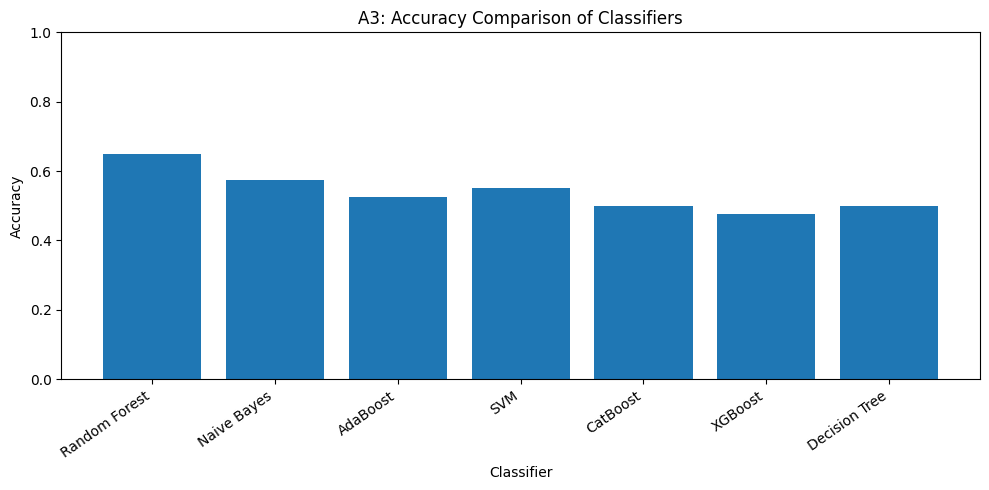

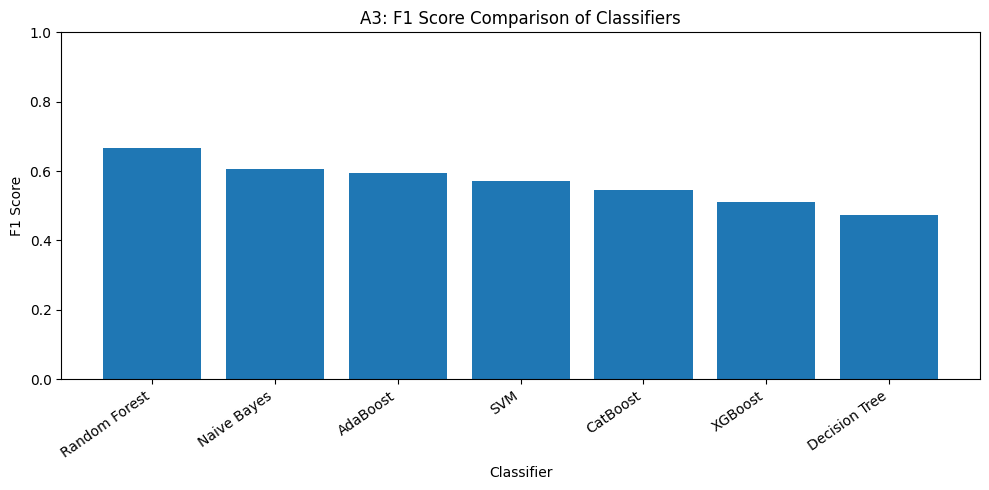

A4: PIPELINE-BASED CLASSIFICATION

Pipeline Performance Comparison:


,Pipeline,Accuracy,Precision,Recall,F1 Score,Execution Time (s)
0,MLP,0.575,0.5556,0.75,0.6383,0.0357
1,Perceptron,0.550,0.5417,0.65,0.5909,0.0096
2,SVM,0.550,0.5455,0.60,0.5714,0.0124



Best pipeline based on F1 Score: MLP

Classification Report:
              precision    recall  f1-score   support

      Benign       0.62      0.40      0.48        20
   Malignant       0.56      0.75      0.64        20

    accuracy                           0.57        40
   macro avg       0.59      0.57      0.56        40
weighted avg       0.59      0.57      0.56        40

Confusion Matrix:
[[ 8 12]
 [ 5 15]]
A5: LIME EXPLANATION OF CLASSIFICATION PIPELINE
Actual class: Benign
Predicted class: Malignant
Benign probability: 0.1858
Malignant probability: 0.8142

Top LIME Feature Contributions:


,Feature,Contribution
0,Pixel_4_4 <= 0.65,-0.066066
1,Pixel_11_7 <= 0.65,-0.059903
2,Pixel_3_6 <= 0.63,0.057755
3,Pixel_9_6 <= 0.65,0.055049
4,Pixel_4_14 <= 0.62,-0.050148
5,Pixel_1_15 <= 0.61,0.046470
6,Pixel_1_12 <= 0.64,-0.046267
7,Pixel_6_6 <= 0.65,-0.042959
8,Pixel_6_10 <= 0.64,0.042834
9,Pixel_3_12 <= 0.63,0.042342


In [ ]:
print("=" * 65)
print("A2: RANDOMIZED SEARCH CV FOR PERCEPTRON AND MLP")
print("=" * 65)

(
    a2_results,
    a2_searches,
    X_train_a2,
    X_test_a2,
    y_train_a2,
    y_test_a2
) = tune_perceptron_and_mlp(X_project, y_project)

print("\nPerformance Comparison:")
display(a2_results.round(4))

for model_name, search in a2_searches.items():
    print(f"\n{model_name}")
    print("-" * 50)
    print(f"Best CV Accuracy: {search.best_score_:.4f}")
    print("Best Hyperparameters:")

    for parameter, value in search.best_params_.items():
        print(f"{parameter}: {value}")

    predictions = search.best_estimator_.predict(X_test_a2)

    print("\nClassification Report:")
    print(
        classification_report(
            y_test_a2,
            predictions,
            labels=[0, 1],
            target_names=["Benign", "Malignant"],
            zero_division=0
        )
    )

    print("Confusion Matrix:")
    print(confusion_matrix(y_test_a2, predictions, labels=[0, 1]))


    print("=" * 65)
print("A3: CLASSIFIER PERFORMANCE COMPARISON")
print("=" * 65)

a3_results, a3_models = compare_classifiers(
    X_train_a2,
    X_test_a2,
    y_train_a2,
    y_test_a2
)

display(a3_results.round(4))

print("\nBest classifier based on F1 Score:")
print(a3_results.iloc[0]["Classifier"])

print("\nBest F1 Score:")
print(round(a3_results.iloc[0]["F1 Score"], 4))


plt.figure(figsize=(10, 5))
plt.bar(
    a3_results["Classifier"],
    a3_results["Accuracy"]
)
plt.title("A3: Accuracy Comparison of Classifiers")
plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(
    a3_results["Classifier"],
    a3_results["F1 Score"]
)
plt.title("A3: F1 Score Comparison of Classifiers")
plt.xlabel("Classifier")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



print("=" * 65)
print("A4: PIPELINE-BASED CLASSIFICATION")
print("=" * 65)

a4_results, a4_pipelines = run_classification_pipelines(
    X_train_a2,
    X_test_a2,
    y_train_a2,
    y_test_a2
)

print("\nPipeline Performance Comparison:")
display(a4_results.round(4))

best_pipeline_name = a4_results.iloc[0]["Pipeline"]
best_pipeline = a4_pipelines[best_pipeline_name]

print("\nBest pipeline based on F1 Score:", best_pipeline_name)

best_predictions = best_pipeline.predict(X_test_a2)

print("\nClassification Report:")
print(
    classification_report(
        y_test_a2,
        best_predictions,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test_a2, best_predictions, labels=[0, 1]))



print("=" * 65)
print("A5: LIME EXPLANATION OF CLASSIFICATION PIPELINE")
print("=" * 65)

(
    a5_explainer,
    a5_explanation,
    a5_feature_results,
    a5_instance,
    a5_actual,
    a5_predicted,
    a5_probabilities
) = explain_pipeline_with_lime(
    pipeline=a4_pipelines["MLP"],
    X_train=X_train_a2,
    X_test=X_test_a2,
    y_test=y_test_a2,
    instance_index=0,
    num_features=10,
    num_samples=2000
)

print("Actual class:", ["Benign", "Malignant"][a5_actual])
print("Predicted class:", ["Benign", "Malignant"][a5_predicted])
print(f"Benign probability: {a5_probabilities[0]:.4f}")
print(f"Malignant probability: {a5_probabilities[1]:.4f}")

print("\nTop LIME Feature Contributions:")
display(a5_feature_results)

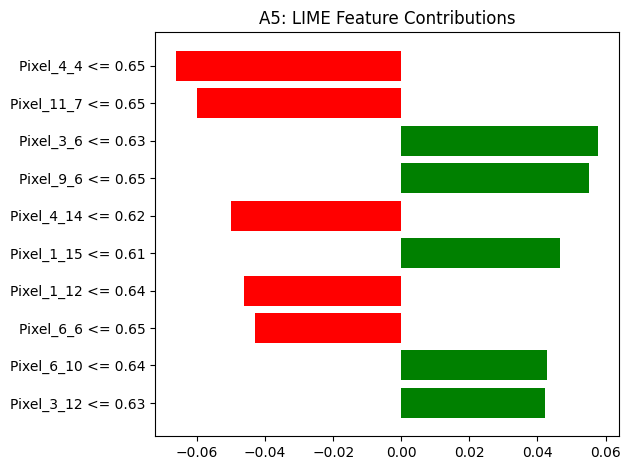

In [ ]:
a5_explanation.as_pyplot_figure(label=a5_predicted)
plt.title("A5: LIME Feature Contributions")
plt.tight_layout()
plt.show()

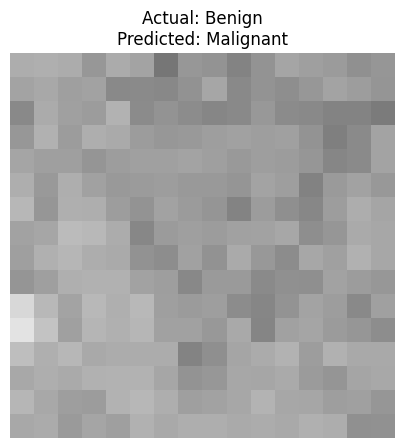

In [ ]:
plt.figure(figsize=(5, 5))
plt.imshow(
    a5_instance.reshape(IMAGE_SIZE),
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title(
    f"Actual: {['Benign', 'Malignant'][a5_actual]}\n"
    f"Predicted: {['Benign', 'Malignant'][a5_predicted]}"
)
plt.axis("off")
plt.show()